# Present Your Solution

Presentation checklist:
1. Big picture first - what problem, what we built
2. Why it meets the business goal (catching sick squirrels)
3. Interesting stuff along the way - what worked, what didn't, assumptions, limitations
4. Key findings as good plots / easy to remember numbers

Nutosis is spreading through the squirrels in Central Park, and right now workers have to read through app sightings to decide which squirrels to go capture and treat. We built a model that takes a squirrel sighting and predicts if the squirrel has nutosis, so the department knows where to send workers. Since missing a sick squirrel is a lot worse than a false alarm, we focused on recall over precision (F2 score).

### Imports

In [1]:
import json
import pickle

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.inspection import permutation_importance
from sklearn.metrics import (ConfusionMatrixDisplay, fbeta_score, make_scorer, precision_recall_curve,
                             precision_score, recall_score)

from custom_transformers import *

from sklearn import set_config
set_config(transform_output="pandas")

### Load final model + test set

In [2]:
TARGET_COL = "is_diseased"

# model.pkl = preprocessor + model, so it takes the raw test set
with open("model.pkl", "rb") as f:
    model = pickle.load(f)

with open("model_comparison.json") as f:
    comparison = json.load(f)

test_set = pd.read_parquet("test_set.parquet")
X_test = test_set.drop(columns=TARGET_COL)
y_test = test_set[TARGET_COL].copy()

test_proba = model.predict_proba(X_test)[:, 1]
test_preds = model.predict(X_test)
print("final model:", comparison["final_model"])

final model: hgb


## Headline Numbers

In [3]:
n_sick = int(y_test.sum())
caught = int(((test_preds == 1) & (y_test == 1)).sum())
flagged = int(test_preds.sum())
false_alarms = flagged - caught

print(f"test sightings:           {len(y_test)}")
print(f"actually sick:            {n_sick}")
print(f"sick ones we caught:      {caught} / {n_sick}  (recall {recall_score(y_test, test_preds):.0%})")
print(f"squirrels we'd dispatch:  {flagged}  ({flagged / len(y_test):.0%} of sightings)")
print(f"  of those, really sick:  {caught}  (precision {precision_score(y_test, test_preds):.0%})")
print(f"  false alarms:           {false_alarms}")
print(f"F2 score:                 {fbeta_score(y_test, test_preds, beta=2):.3f}")

test sightings:           605
actually sick:            76
sick ones we caught:      55 / 76  (recall 72%)
squirrels we'd dispatch:  158  (26% of sightings)
  of those, really sick:  55  (precision 35%)
  false alarms:           103
F2 score:                 0.595


On new sightings, our model catches about 3 out of every 4 sick squirrels while sending workers out to about 1 in 4 sightings.

## Model Comparison

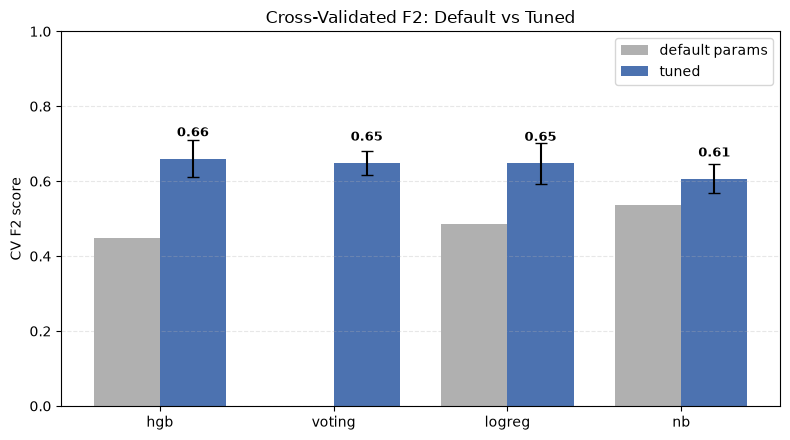

In [4]:
# CV F2 before (default params) vs after tuning, from the Training notebook
default = pd.DataFrame(comparison["default"]).T
tuned = pd.DataFrame(comparison["tuned"]).T

models = list(tuned.index)
x = np.arange(len(models))
w = 0.38

fig, ax = plt.subplots(figsize=(8, 4.5))
before = [default.loc[m, "f2"] if m in default.index else np.nan for m in models]
ax.bar(x - w / 2, before, w, label="default params", color="#B0B0B0")
ax.bar(x + w / 2, tuned["f2"], w, yerr=tuned["f2_std"], capsize=4, label="tuned", color="#4C72B0")
for i, v in enumerate(tuned["f2"]):
    ax.text(i + w / 2, v + 0.06, f"{v:.2f}", ha="center", fontsize=9, fontweight="bold")

ax.set_xticks(x)
ax.set_xticklabels(models)
ax.set_ylabel("CV F2 score")
ax.set_ylim(0, 1)
ax.set_title("Cross-Validated F2: Default vs Tuned")
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

Tuning helped every model a lot, mostly from `class_weight` telling the models that sick squirrels matter more. hgb went from 0.45 to 0.66 F2, and logreg from 0.49 to 0.65. We also tried a voting ensemble, but it didn't beat hgb on its own (0.65), so we went with hgb since it had the best score and is just one model.

## Test Set Results

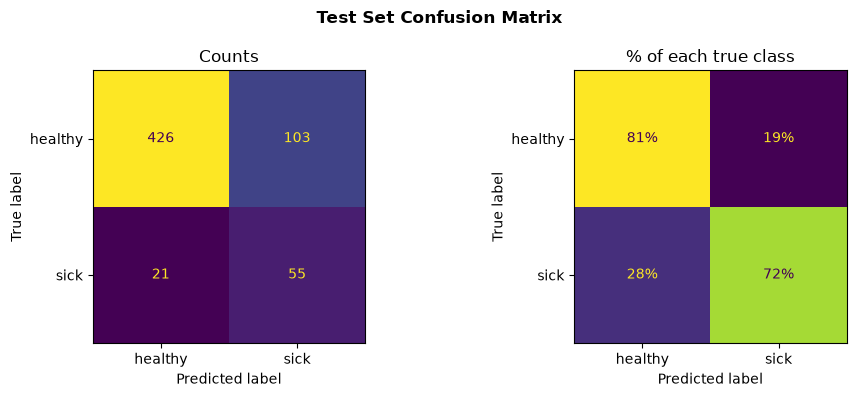

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(y_test, test_preds, display_labels=["healthy", "sick"],
                                        colorbar=False, ax=axes[0])
axes[0].set_title("Counts")
ConfusionMatrixDisplay.from_predictions(y_test, test_preds, display_labels=["healthy", "sick"],
                                        normalize="true", values_format=".0%", colorbar=False, ax=axes[1])
axes[1].set_title("% of each true class")
plt.suptitle("Test Set Confusion Matrix", fontweight="bold")
plt.tight_layout()
plt.show()

### Recall vs Precision Tradeoff

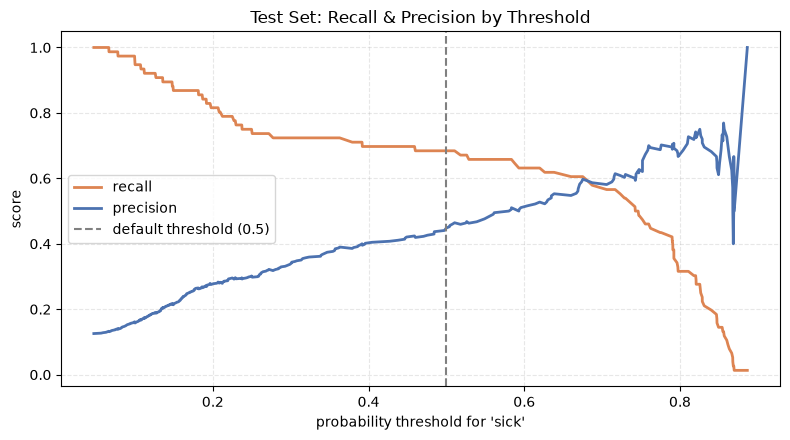

In [6]:
# moving the threshold trades false alarms for caught squirrels
precision, recall, thresholds = precision_recall_curve(y_test, test_proba)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(thresholds, recall[:-1], label="recall", color="#DD8452", linewidth=2)
ax.plot(thresholds, precision[:-1], label="precision", color="#4C72B0", linewidth=2)
ax.axvline(0.5, color="gray", linestyle="--", label="default threshold (0.5)")
ax.set_xlabel("probability threshold for 'sick'")
ax.set_ylabel("score")
ax.set_title("Test Set: Recall & Precision by Threshold")
ax.legend()
ax.grid(linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

In [7]:
# what each threshold means for dispatching (test set)
rows = []
for t in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6]:
    p = (test_proba >= t).astype(int)
    rows.append({
        "threshold": t,
        "recall": recall_score(y_test, p),
        "precision": precision_score(y_test, p, zero_division=0),
        "F2": fbeta_score(y_test, p, beta=2),
        "sick caught": int(((p == 1) & (y_test == 1)).sum()),
        "dispatches": int(p.sum()),
        "% of sightings dispatched": p.mean(),
    })
pd.DataFrame(rows).set_index("threshold").style.format({
    "recall": "{:.0%}", "precision": "{:.0%}", "F2": "{:.3f}", "% of sightings dispatched": "{:.0%}",
})

,recall,precision,F2,sick caught,dispatches,% of sightings dispatched
threshold,,,,,,
0.100000,95%,16%,0.474,72,456,75%
0.200000,82%,28%,0.588,62,223,37%
0.300000,72%,34%,0.590,55,162,27%
0.400000,70%,40%,0.609,53,131,22%
0.500000,68%,45%,0.621,52,115,19%
0.600000,63%,52%,0.605,48,93,15%


- This table uses the test set, so it's really just here to show the tradeoff. If we want to actually pick a threshold, we should use CV on the training set instead.
- This table uses the same threshold for every squirrel. Our final model uses 0.3 for gray and 0.5 for everyone else, so its numbers aren't any one row here.
- Moving the threshold from 0.5 down to 0.2 takes us from catching 68% to 82% of sick squirrels, but dispatches almost double (115 -> 223). Going all the way to 0.1 catches 95%, but then we're sending someone out for 75% of sightings, which is basically checking everything.

Going forward, it seems like lowering it for everyone is a waste, since cinnamon and black squirrels already get caught at 0.5. That's why we only lowered it for gray (see the gray section below).

## What Drives Predictions

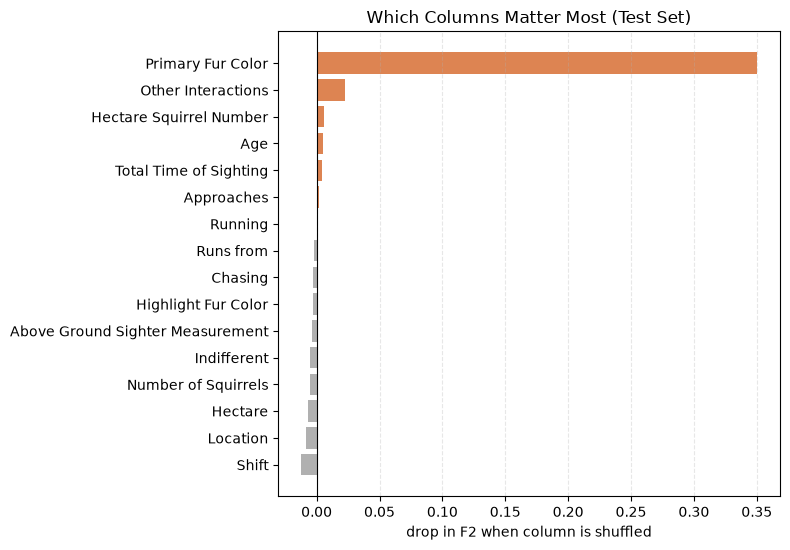

In [8]:
# permutation importance on the RAW columns (whole pipeline), so names are easy to read
result = permutation_importance(model, X_test, y_test, scoring=make_scorer(fbeta_score, beta=2),
                                n_repeats=5, random_state=42)
importance = pd.Series(result.importances_mean, index=X_test.columns).sort_values()
importance = importance[importance.abs() > 0.001]   # skip columns the model ignores

fig, ax = plt.subplots(figsize=(8, max(3, 0.35 * len(importance))))
colors = ["#DD8452" if v > 0 else "#B0B0B0" for v in importance]
ax.barh(importance.index, importance.values, color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("drop in F2 when column is shuffled")
ax.set_title("Which Columns Matter Most (Test Set)")
ax.grid(axis="x", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

Same story as exploration, but way more extreme. `Primary Fur Color` is by far the most important column, and everything else barely moves the score. The text notes (`Other Activities` and `Other Interactions`) come in next, which is nice to see since we put a lot of work into the anchors. Some columns like `Hectare` and `Highlight Fur Color` actually come out slightly negative, so the model would do about the same without them.

## Where the Model Hits and Misses

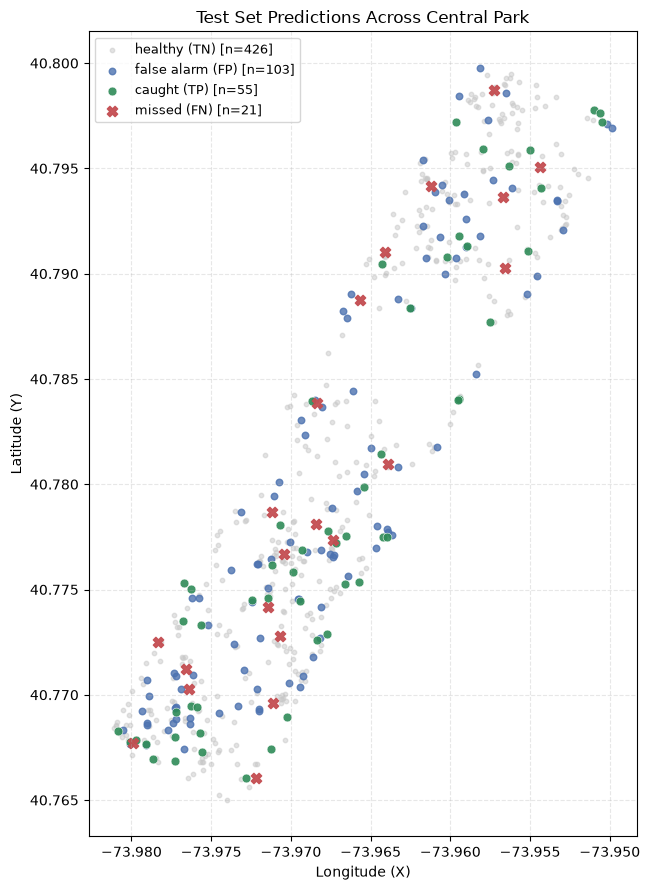

In [9]:
# test sightings on the park map, colored by outcome
outcome = np.select(
    [(test_preds == 1) & (y_test == 1), (test_preds == 0) & (y_test == 1), (test_preds == 1) & (y_test == 0)],
    ["caught (TP)", "missed (FN)", "false alarm (FP)"],
    default="healthy (TN)",
)
styles = {
    "healthy (TN)": dict(color="#C8C8C8", s=10, alpha=0.5),
    "false alarm (FP)": dict(color="#4C72B0", s=22, alpha=0.8),
    "caught (TP)": dict(color="#2E8B57", s=40, alpha=0.9, edgecolors="white", linewidths=0.4),
    "missed (FN)": dict(color="#C44E52", s=55, alpha=0.95, marker="X"),
}

fig, ax = plt.subplots(figsize=(7.5, 9))
for label, style in styles.items():
    mask = outcome == label
    ax.scatter(test_set.loc[mask, "X"], test_set.loc[mask, "Y"], label=f"{label} [n={mask.sum()}]", **style)

ax.set_aspect(1 / np.cos(np.radians(test_set["Y"].mean())))   # keep the park's real shape
ax.set_xlabel("Longitude (X)")
ax.set_ylabel("Latitude (Y)")
ax.set_title("Test Set Predictions Across Central Park")
ax.legend(loc="upper left", fontsize=9)
ax.grid(linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

In [10]:
# what do the missed sick squirrels look like vs the caught ones?
sick = test_set[y_test == 1].copy()
sick["outcome"] = np.where(test_preds[y_test.values == 1] == 1, "caught", "missed")
pd.DataFrame({
    "primary fur": sick.groupby("outcome")["Primary Fur Color"].agg(lambda s: s.value_counts(normalize=True).round(2).to_dict()),
    "approaches": sick.groupby("outcome")["Approaches"].mean().round(2),
    "runs from": sick.groupby("outcome")["Runs from"].mean().round(2),
    "count": sick.groupby("outcome").size(),
})

,primary fur,approaches,runs from,count
outcome,,,,
caught,"{'Cinnamon': 0.7, 'Black': 0.2, 'Gray': 0.09}",0.20,0.24,55
missed,{'Gray': 1.0},0.14,0.24,21


Yes, a really clear one. Every single missed squirrel is gray. Even with the lower gray threshold, 90% of the caught ones are still cinnamon or black, and we only caught 5 of the 26 sick gray squirrels. Behavior doesn't look very different between the two groups (approaches 20% vs 14%). The misses are also spread all over the park on the map, so it doesn't seem to be a location thing. So basically our model is mostly just flagging cinnamon and black squirrels, and it can't really find the sick gray ones.

## Gray Squirrel Blind Spot

In [11]:
# out-of-fold predictions on the TRAINING set (CV), so we don't tune anything on the test set
from sklearn.base import clone
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict

train_set = pd.read_parquet("train_set.parquet")
X_train = train_set.drop(columns=TARGET_COL)
y_train = train_set[TARGET_COL].values

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
oof_proba = cross_val_predict(clone(model), X_train, y_train, groups=train_set["Unique Squirrel ID"],
                              cv=cv, method="predict_proba")[:, 1]
fur = train_set["Primary Fur Color"].fillna("Missing")
is_gray = (fur == "Gray").values

In [12]:
# how well do we do per fur color at the normal 0.5 threshold?
oof_pred = (oof_proba >= 0.5).astype(int)
rows = []
for color in fur.value_counts().index:
    m = (fur == color).values
    rows.append({
        "fur": color,
        "squirrels": int(m.sum()),
        "sick": int(y_train[m].sum()),
        "sick rate": y_train[m].mean(),
        "sick caught (recall)": recall_score(y_train[m], oof_pred[m], zero_division=0),
        "AUC": roc_auc_score(y_train[m], oof_proba[m]) if 0 < y_train[m].sum() < m.sum() else np.nan,
    })
pd.DataFrame(rows).set_index("fur").style.format({
    "sick rate": "{:.1%}", "sick caught (recall)": "{:.0%}", "AUC": "{:.3f}",
})

,squirrels,sick,sick rate,sick caught (recall),AUC
fur,,,,,
Gray,1977,89,4.5%,10%,0.593
Cinnamon,312,150,48.1%,99%,0.625
Black,85,56,65.9%,100%,0.717
Missing,44,8,18.2%,100%,0.406


In [13]:
# what if gray squirrels got their own (lower) threshold? other colors stay at 0.5
rows = []
for t in [0.5, 0.4, 0.3, 0.2, 0.15, 0.1]:
    pred = np.where(is_gray, oof_proba >= t, oof_proba >= 0.5).astype(int)
    rows.append({
        "gray threshold": t,
        "sick gray caught": recall_score(y_train[is_gray], pred[is_gray]),
        "all sick caught": recall_score(y_train, pred),
        "precision": precision_score(y_train, pred),
        "% of sightings dispatched": pred.mean(),
        "F2": fbeta_score(y_train, pred, beta=2),
    })
gray_tradeoff = pd.DataFrame(rows).set_index("gray threshold")
gray_tradeoff.style.format({c: "{:.0%}" for c in gray_tradeoff.columns if c != "F2"} | {"F2": "{:.3f}"}).format_index("{:.2f}")

,sick gray caught,all sick caught,precision,% of sightings dispatched,F2
gray threshold,,,,,
0.50,10%,73%,47%,19%,0.660
0.40,18%,76%,43%,22%,0.655
0.30,28%,79%,34%,29%,0.623
0.20,45%,83%,25%,42%,0.569
0.15,56%,87%,20%,54%,0.522
0.10,74%,92%,16%,74%,0.464


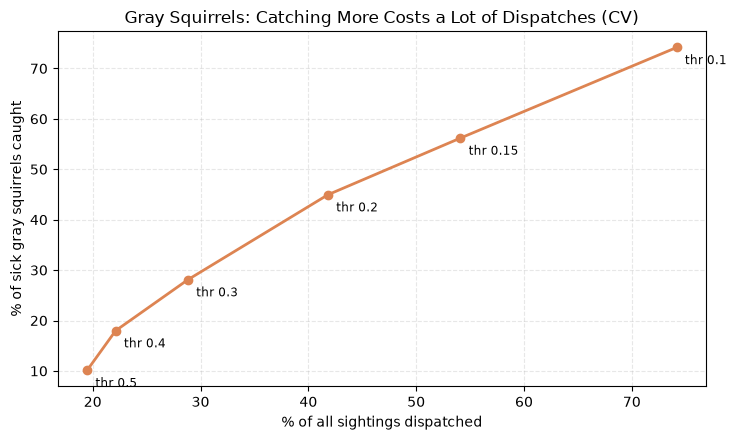

In [14]:
# same tradeoff as a picture: more gray caught = a lot more dispatches
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.plot(gray_tradeoff["% of sightings dispatched"] * 100, gray_tradeoff["sick gray caught"] * 100,
        marker="o", color="#DD8452", linewidth=2)
for t, r in gray_tradeoff.iterrows():
    ax.annotate(f"thr {t}", (r["% of sightings dispatched"] * 100, r["sick gray caught"] * 100),
                textcoords="offset points", xytext=(6, -12), fontsize=8.5)
ax.set_xlabel("% of all sightings dispatched")
ax.set_ylabel("% of sick gray squirrels caught")
ax.set_title("Gray Squirrels: Catching More Costs a Lot of Dispatches (CV)")
ax.grid(linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

- Gray is hard because there's only ~89 sick gray squirrels in training, and only ~4.5% of gray squirrels are sick. The behavior signals we have are pretty weak for them too. In CV we only catch 10% of sick gray squirrels at 0.5, and the AUC is 0.593, which is not much better than guessing.
- Giving gray squirrels a lower threshold does work, but it's expensive. At a gray threshold of 0.3 we'd catch 79% of all sick squirrels with 29% of sightings dispatched. At 0.2, we catch 83% but dispatch 42%.
- We went with 0.3 for gray in the final model. Going from 0.5 to 0.3 gets us more for the extra dispatches than going from 0.3 to 0.2 does.

Question for the client: is 0.3 the right amount of extra dispatches, or is the budget there to go lower?

## Wrap Up

- **What worked:** fur color carried most of the signal, and using `class_weight` + F2 scoring made a big difference for recall. Splitting hectare into row/col also worked out, since tuning ended up dropping X/Y for all 3 models. The lower gray threshold also got recall up a bit (68% -> 72% on test).
- **What didn't:** the ensemble didn't beat hgb, and the model still can't really find the sick gray squirrels, even with the lower threshold.
- **Assumptions we made:** the diseased list is correct, false alarms are okay since treatment is cheap (we used about 5:1 for a miss vs a false alarm), and app sightings will look like census sightings.
- **Limitations:** the data is only 11 days from October 2018, so we don't know if this holds for other seasons. Some of our features (hectare info, number of sighters, time of sighting) come from how the census was run, and new app sightings might not have them. And the model is really leaning on fur color, so if sick gray squirrels become more common it would miss most of them.